# **ЛАБОРАТОРНА РОБОТА 5**
## **Сегментація зображень. Дизеринг Флойда–Стейнберга.**

In [7]:
import cv2
import numpy as np
from matplotlib import pyplot as plt

### 1. Функція квантування зображення
$$
d(p,c)=\sqrt{\sum_{k=1}^{3}(p_k-c_k)^2}
$$

$$
MAE=\frac{1}{N}\sum_{i=1}^{N}|I_i-Q_i|
$$

In [8]:
def quantize_image(img, colors):
    rows, cols, _ = img.shape
    quantized = np.zeros_like(img)

    for r in range(rows):
        for c in range(cols):
            
            pixel = img[r, c, :]

            distances = np.linalg.norm(colors - pixel, axis=1)
            new_pixel = colors[np.argmin(distances)]

            quantized[r, c, :] = new_pixel

    avg_quant_error = np.mean(np.abs(img.astype(float) - quantized.astype(float)))

    return quantized, avg_quant_error

### 2. Дизеринг Флойда–Стейнберга

In [ ]:
def floyd_steinberg_dithering(img, colors):
    
    rows, cols, _ = img.shape
    
    img_tmp = np.copy(img).astype(float)
    dithering = np.zeros_like(img)

    for r in range(rows):
        for c in range(cols):
            
            pixel = img_tmp[r, c, :]
            
            distances = np.linalg.norm(colors - pixel, axis=1)
            new_pixel = colors[np.argmin(distances)]
            
            quant_error = pixel - new_pixel

            if c + 1 < cols:
                img_tmp[r, c + 1, :] += quant_error * 7 / 16

            if r + 1 < rows and c - 1 >= 0:
                img_tmp[r + 1, c - 1, :] += quant_error * 3 / 16

            if r + 1 < rows:
                img_tmp[r + 1, c, :] += quant_error * 5 / 16

            if r + 1 < rows and c + 1 < cols:
                img_tmp[r + 1, c + 1, :] += quant_error * 1 / 16

            dithering[r, c, :] = new_pixel

    avg_dith_error = np.mean(np.abs(img.astype(float) - dithering.astype(float)))

    return dithering, avg_dith_error


### 3. Основна функція

In [10]:
def main(img, colors):
    
    quantized, quant_error = quantize_image(img, colors)
    dithering, dith_error = floyd_steinberg_dithering(img, colors)

    plt.figure(figsize=(12, 5))

    plt.subplot(1, 2, 1)
    plt.imshow(quantized)
    plt.title(f"Квантування")
    plt.axis("off")

    plt.subplot(1, 2, 2)
    plt.imshow(dithering)
    plt.title(f"Floyd-Steinberg dithering")
    plt.axis("off")

    plt.tight_layout()
    plt.show()

    print(f"Середня похибка квантування: {quant_error:.2f}")
    print(f"Середня похибка дизерингу: {dith_error:.2f}")

### 4. Результат

In [ ]:
colors_1 = np.array([
    [0, 0, 0],
    [255, 255, 255],
    [255, 0, 0],
    [0, 255, 0]
])

colors_2 = np.array([
    [0, 0, 0],
    [255, 255, 255],
    [255, 140, 0],
    [255, 255, 0]
])

colors_3 = np.array([
    [0, 0, 0],
    [255, 255, 255],
    [0, 100, 0],
    [150, 200, 100]
])

images = {
    'parrot': ('kodim23.png', colors_1),
    'sunset': ('sunset.jpg', colors_2),
    'tree': ('tree.jpg', colors_3)
}

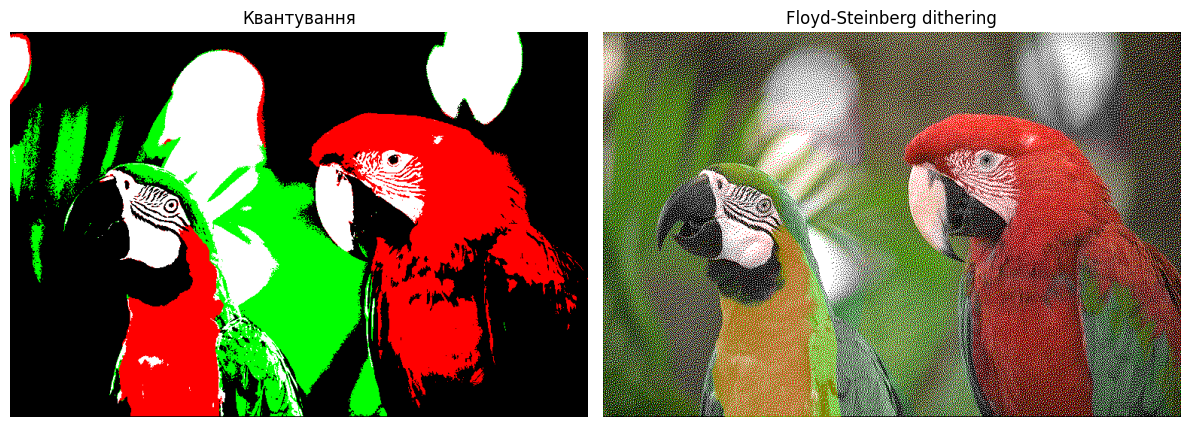

Середня похибка квантування: 75.53
Середня похибка дизерингу: 98.92


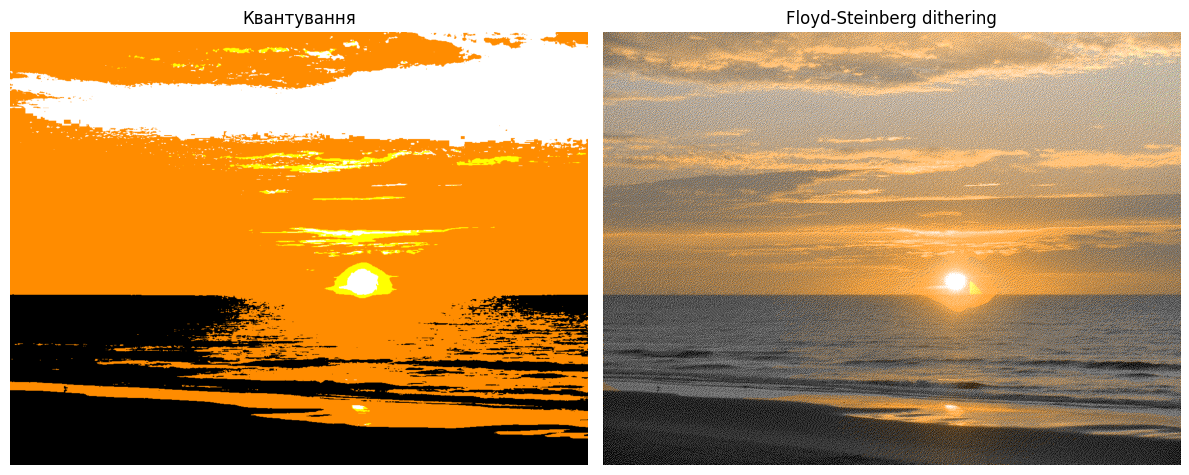

Середня похибка квантування: 67.38
Середня похибка дизерингу: 97.47


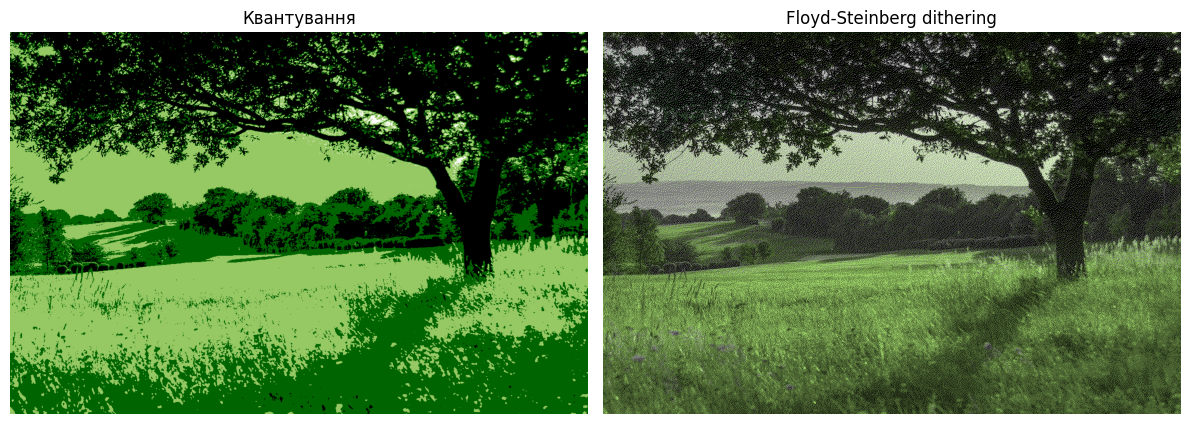

Середня похибка квантування: 39.41
Середня похибка дизерингу: 65.96


In [12]:
for name, (filename, colors) in images.items():
    
    img = cv2.imread(filename)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    main(img, colors)